# 01 · Exploratory Data Analysis
**Credora Finance — Credit Risk & Loan Approval Analytics Platform**

**Goal of this notebook:** understand the data *before* modelling. We want to know
1. how the four tables fit together and whether the data is trustworthy,
2. how imbalanced the target (`loan_default`) is,
3. which customer / credit / loan characteristics are linked to default,
4. what traps we must avoid in feature engineering (leakage, duplicated rows, redundant columns).

**How to run:** run `python src/data_load.py` first so MySQL is filled, make sure `.env` has your
MySQL login, then run the cells top to bottom (*Run All*).

**Rule for this notebook:** analysis of *default* uses only **disbursed loans** (3,403 rows) because
that is the only population where the outcome is known — exactly the population the model will train on.

## 1 · Setup and database connection

In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11})
pd.set_option("display.max_columns", 50, "display.width", 200)

# Works whether Jupyter was started in the project root or in notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
load_dotenv(ROOT / ".env")

engine = create_engine(URL.create(
    "mysql+pymysql",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    host=os.getenv("DB_HOST", "localhost"),
    port=int(os.getenv("DB_PORT", "3306")),
    database=os.getenv("DB_NAME", "credora_risk"),
))
print("Connected to database:", os.getenv("DB_NAME", "credora_risk"))

Connected to database: credora_risk


## 2 · Load the four tables

In [2]:
customers = pd.read_sql("SELECT * FROM customers", engine)
credit    = pd.read_sql("SELECT * FROM credit_history", engine)
loans     = pd.read_sql("SELECT * FROM loan_applications", engine)
txn       = pd.read_sql("SELECT * FROM transactions", engine)

# MySQL returns DATE columns as Python date objects -> convert to proper datetimes
for df, cols in [(customers, ["date_of_birth", "customer_since"]),
                 (credit, ["as_of_date"]),
                 (loans, ["application_date", "decision_date"]),
                 (txn, ["transaction_date"])]:
    for c in cols:
        df[c] = pd.to_datetime(df[c])

summary = pd.DataFrame({
    "table": ["customers", "credit_history", "loan_applications", "transactions"],
    "rows": [len(customers), len(credit), len(loans), len(txn)],
    "columns": [customers.shape[1], credit.shape[1], loans.shape[1], txn.shape[1]],
})
summary

,table,rows,columns
0,customers,5000,20
1,credit_history,5000,14
2,loan_applications,7500,17
3,transactions,40079,8


## 3 · Data quality checks
Missing values first. Some NULLs are **expected and valid**: `loan_default` is empty for loans that were never
disbursed, and `decision_date` is empty for applications still under review.

In [3]:
missing = {}
for name, df in [("customers", customers), ("credit_history", credit),
                 ("loan_applications", loans), ("transactions", txn)]:
    n = df.isna().sum()
    for col, v in n[n > 0].items():
        missing[f"{name}.{col}"] = v

print("Columns with missing values (everything else is complete):")
print(pd.Series(missing, name="missing_rows").to_frame())

Columns with missing values (everything else is complete):
                                 missing_rows
loan_applications.decision_date           173
loan_applications.loan_default           4097


In [4]:
# Redundancy / consistency checks
ratio = (loans.merge(customers[["customer_id", "annual_income"]], on="customer_id")
              .eval("applicant_monthly_income * 12 / annual_income"))
print(f"monthly income x 12 / annual income:  min={ratio.min():.2f}  max={ratio.max():.2f}")
print("-> identical in every row, so these two columns carry the SAME information.\n")

print("Distinct bureau snapshot dates in credit_history:", credit["as_of_date"].nunique(),
      "->", credit["as_of_date"].dt.date.unique()[0])
print("-> every customer has ONE snapshot (30 Jun 2024). There is no credit-score history over time.\n")

per_cust = txn.groupby("customer_id").size()
print(f"Transactions per customer: min={per_cust.min()}, median={per_cust.median():.0f}, max={per_cust.max()}")
print("-> only a handful of transactions per customer, so transaction features will be fairly noisy.")

monthly income x 12 / annual income:  min=1.00  max=1.00
-> identical in every row, so these two columns carry the SAME information.

Distinct bureau snapshot dates in credit_history: 1 -> 2024-06-30
-> every customer has ONE snapshot (30 Jun 2024). There is no credit-score history over time.

Transactions per customer: min=4, median=8, max=12
-> only a handful of transactions per customer, so transaction features will be fairly noisy.


## 4 · Build the analysis table (disbursed loans only)
We join each loan to its customer and bureau record. Email, phone and names are **dropped** (PII, not predictive —
the PRD excludes them from modelling and dashboards).

In [5]:
master = (loans
          .merge(customers.drop(columns=["first_name", "last_name", "email", "phone", "date_of_birth"]),
                 on="customer_id", how="left")
          .merge(credit.drop(columns=["credit_id", "as_of_date"]), on="customer_id", how="left"))
assert len(master) == len(loans), "join duplicated rows!"

d = master[master["loan_default"].notna()].copy()
d["loan_default"] = d["loan_default"].astype(int)
d["status"] = d["loan_default"].map({0: "Repaid", 1: "Default"})
d["collateral"] = d["collateral_flag"].map({0: "No collateral", 1: "Collateral"})

# Analysis bands (also reused later in the dashboard)
d["credit_band"] = pd.cut(d["credit_score"], [299, 549, 649, 749, 900],
                          labels=["<550", "550-649", "650-749", "750+"])
d["income_band"] = pd.cut(d["annual_income"], [-1, 300_000, 600_000, 1_500_000, np.inf],
                          labels=["<3L", "3-6L", "6-15L", "15L+"])
d["dti_band"] = pd.cut(d["debt_to_income_ratio"], [0, 0.4, 0.7, 1.0, 1.5, np.inf],
                       labels=["<0.4", "0.4-0.7", "0.7-1.0", "1.0-1.5", ">1.5"])
d["util_band"] = pd.cut(d["credit_utilization_ratio"], [-0.01, 0.3, 0.5, 0.7, 1.0],
                        labels=["<30%", "30-50%", "50-70%", ">70%"])

print(f"Analysis table: {d.shape[0]:,} disbursed loans x {d.shape[1]} columns")
print("Approval status of these loans:", d["approval_status"].unique().tolist())

Analysis table: 3,403 disbursed loans x 48 columns
Approval status of these loans: ['Approved']


## 5 · The target: `loan_default`
How imbalanced is it? This decides which metrics matter (accuracy alone would be misleading).

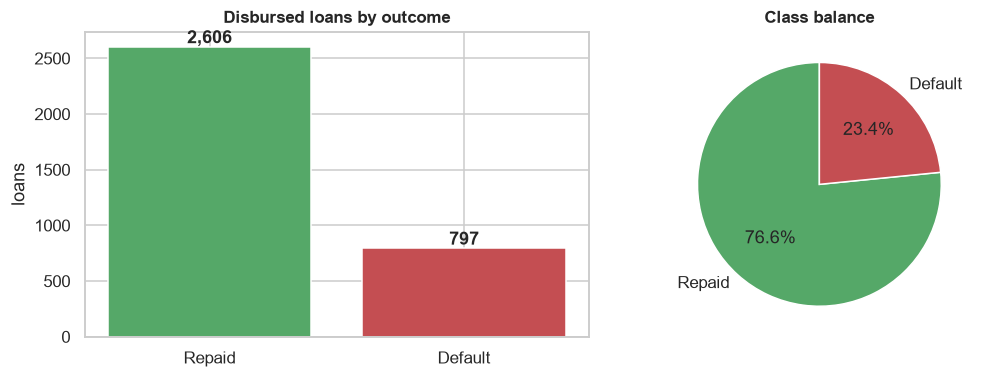

Default rate = 23.4%  ->  about 1 default for every 3.3 repaid loans.
A model that predicts 'Repaid' for everyone would score ~77% accuracy yet catch ZERO defaulters,
so we will judge models on ROC-AUC and recall (as the PRD says), not accuracy.


In [6]:
counts = d["status"].value_counts().reindex(["Repaid", "Default"])
BASE = d["loan_default"].mean() * 100

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].bar(counts.index, counts.values, color=["#55A868", "#C44E52"])
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 30, f"{v:,}", ha="center", fontweight="bold")
ax[0].set_title("Disbursed loans by outcome"); ax[0].set_ylabel("loans")
ax[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%", colors=["#55A868", "#C44E52"],
          startangle=90, wedgeprops={"edgecolor": "white"})
ax[1].set_title("Class balance")
plt.tight_layout(); plt.show()

print(f"Default rate = {BASE:.1f}%  ->  about 1 default for every {counts['Repaid'] / counts['Default']:.1f} repaid loans.")
print("A model that predicts 'Repaid' for everyone would score ~77% accuracy yet catch ZERO defaulters,")
print("so we will judge models on ROC-AUC and recall (as the PRD says), not accuracy.")

## 6 · Default rate by segment
Each bar is the default rate of that group; the **red dashed line is the portfolio average**. The text shows the
share and the number of loans (`n`) so we do not over-read tiny groups.

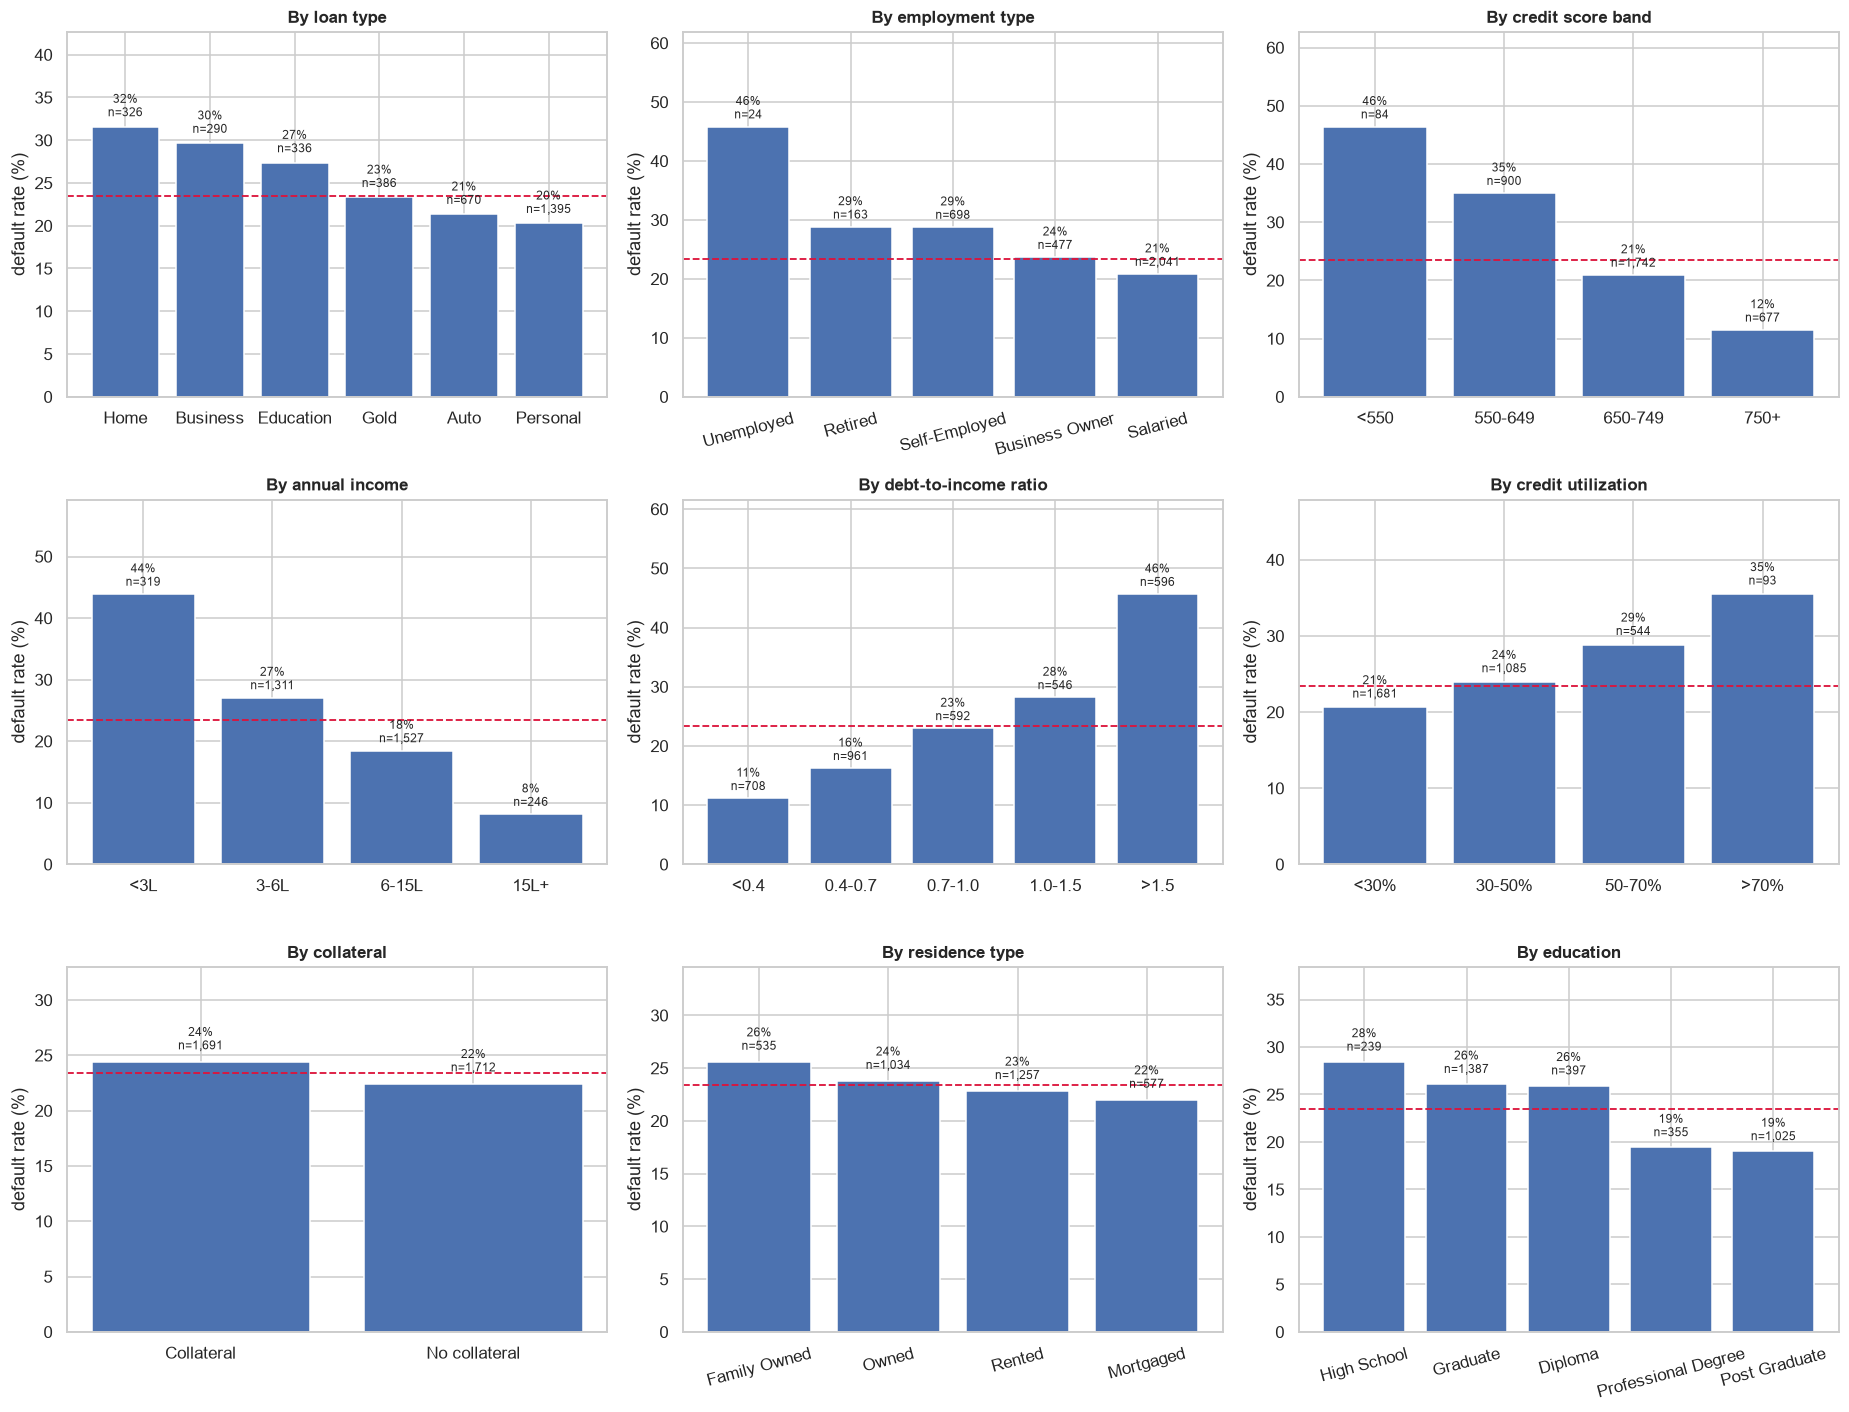

In [7]:
def rate_by(col):
    g = (d.groupby(col, observed=True)["loan_default"].agg(rate="mean", n="size").reset_index())
    g["rate"] *= 100
    return g

def plot_rate(ax, col, title, order_by_rate=False, rot=0):
    g = rate_by(col)
    if order_by_rate:
        g = g.sort_values("rate", ascending=False)
    x = g[col].astype(str)
    ax.bar(x, g["rate"], color="#4C72B0")
    ax.axhline(BASE, color="crimson", ls="--", lw=1.2)
    for i, (r, n) in enumerate(zip(g["rate"], g["n"])):
        ax.text(i, r + 0.8, f"{r:.0f}%\nn={n:,}", ha="center", va="bottom", fontsize=8)
    ax.set_ylim(0, g["rate"].max() * 1.35)
    ax.set_title(title); ax.set_ylabel("default rate (%)"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=rot)

fig, axes = plt.subplots(3, 3, figsize=(17, 13))
plot_rate(axes[0, 0], "loan_type",       "By loan type", order_by_rate=True)
plot_rate(axes[0, 1], "employment_type", "By employment type", order_by_rate=True, rot=15)
plot_rate(axes[0, 2], "credit_band",     "By credit score band")
plot_rate(axes[1, 0], "income_band",     "By annual income")
plot_rate(axes[1, 1], "dti_band",        "By debt-to-income ratio")
plot_rate(axes[1, 2], "util_band",       "By credit utilization")
plot_rate(axes[2, 0], "collateral",      "By collateral")
plot_rate(axes[2, 1], "residence_type",  "By residence type", order_by_rate=True, rot=15)
plot_rate(axes[2, 2], "education",       "By education", order_by_rate=True, rot=15)
plt.tight_layout(); plt.show()

**Reading the charts.** Default rate falls steadily as credit score and income rise and climbs sharply with
debt-to-income. Those three look like the strongest drivers. Segments with a small `n` (for example *Unemployed*)
look extreme but rest on very few loans, so treat them with caution.
Collateral and residence type barely move the rate (within a few points of the average), so they look like **weak**
drivers on their own.

## 7 · Do defaulters look different? Distributions of key numeric features
Histograms are normalised (`density`) so the two groups are comparable despite the 3:1 size difference. Where the
orange (Default) and blue (Repaid) shapes separate, the feature carries signal.

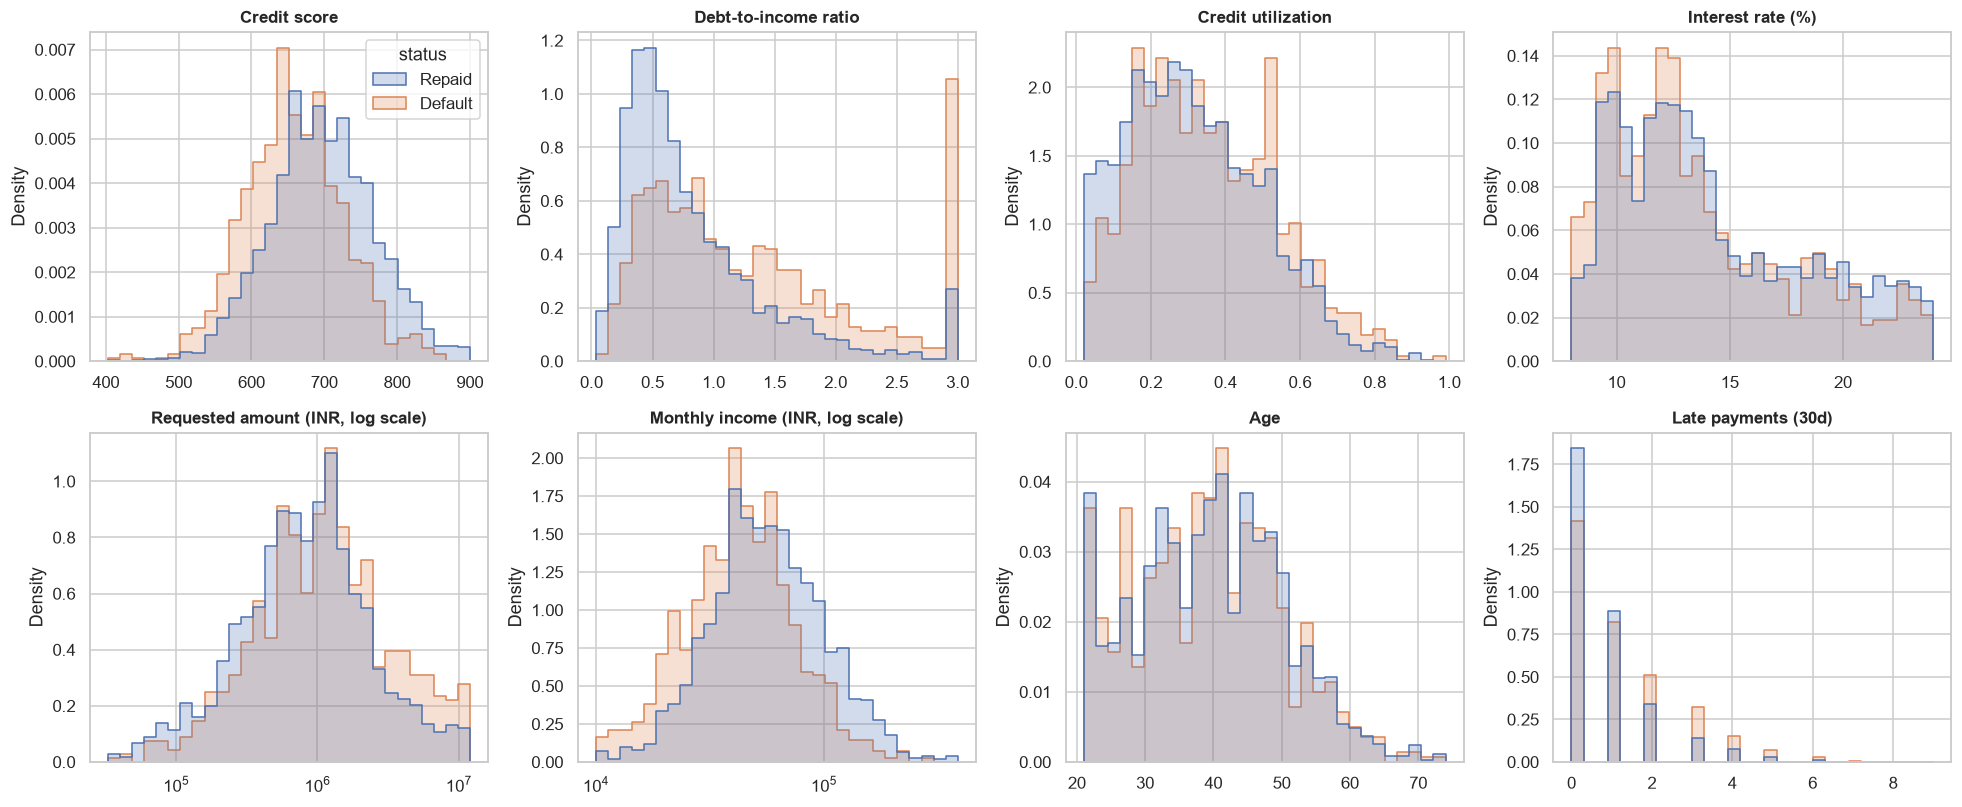

In [8]:
num_cols = ["credit_score", "debt_to_income_ratio", "credit_utilization_ratio", "interest_rate",
            "requested_amount", "applicant_monthly_income", "age", "num_late_payments_30d"]
titles = {"credit_score": "Credit score", "debt_to_income_ratio": "Debt-to-income ratio",
          "credit_utilization_ratio": "Credit utilization", "interest_rate": "Interest rate (%)",
          "requested_amount": "Requested amount (INR, log scale)",
          "applicant_monthly_income": "Monthly income (INR, log scale)",
          "age": "Age", "num_late_payments_30d": "Late payments (30d)"}
log_cols = {"requested_amount", "applicant_monthly_income"}

fig, axes = plt.subplots(2, 4, figsize=(18, 7.5))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(data=d, x=col, hue="status", hue_order=["Repaid", "Default"],
                 stat="density", common_norm=False, element="step", bins=30,
                 log_scale=col in log_cols, palette={"Repaid": "#4C72B0", "Default": "#DD8452"},
                 ax=ax, legend=(col == "credit_score"))
    ax.set_title(titles[col]); ax.set_xlabel("")
plt.tight_layout(); plt.show()

In [9]:
# Same story in numbers: the average of each feature for repaid vs defaulted loans
cmp = (d.groupby("status")[num_cols].mean().T.round(3))
cmp["difference_%"] = ((cmp["Default"] / cmp["Repaid"] - 1) * 100).round(1)

cap = d["debt_to_income_ratio"].max()
at_cap = d["debt_to_income_ratio"] >= cap
print(f"Note: debt-to-income is CAPPED at {cap:.1f} - {at_cap.mean() * 100:.1f}% of loans sit exactly at the cap "
      f"and {d.loc[at_cap, 'loan_default'].mean() * 100:.0f}% of those defaulted.\n")
cmp

Note: debt-to-income is CAPPED at 3.0 - 4.3% of loans sit exactly at the cap and 55% of those defaulted.



status,Default,Repaid,difference_%
credit_score,658.890,696.913,-5.5
debt_to_income_ratio,1.305,0.830,57.2
credit_utilization_ratio,0.354,0.316,12.0
interest_rate,13.699,14.279,-4.1
requested_amount,1939637.390,1398471.988,38.7
applicant_monthly_income,49910.665,66644.551,-25.1
age,39.267,39.577,-0.8
num_late_payments_30d,1.197,0.761,57.3


## 8 · Transaction behaviour
Transactions are at *transaction* grain, but loans are at *loan* grain. Joining them directly would duplicate loan rows,
which is the leakage/duplication trap the PRD warns about. So we first **aggregate to one row per customer**.
(This is a preview — the real feature code goes in `src/features.py`.)

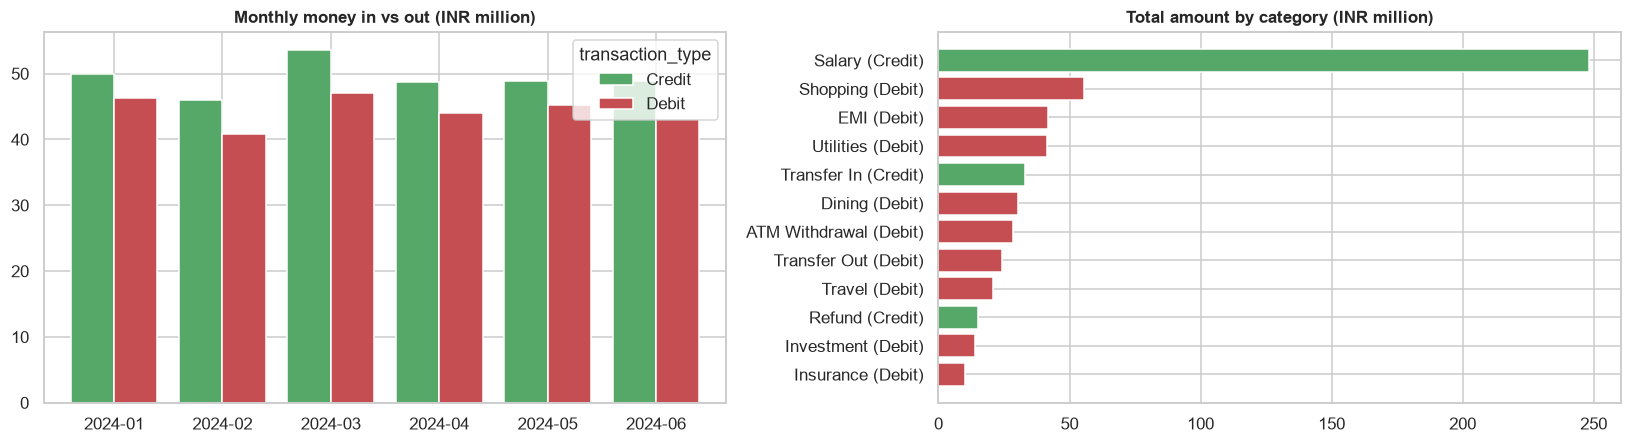

In [10]:
txn["month"] = txn["transaction_date"].dt.to_period("M").astype(str)
monthly = txn.pivot_table(index="month", columns="transaction_type", values="amount", aggfunc="sum") / 1e6

fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
monthly.plot(kind="bar", ax=ax[0], color={"Credit": "#55A868", "Debit": "#C44E52"}, width=0.8)
ax[0].set_title("Monthly money in vs out (INR million)"); ax[0].set_xlabel(""); ax[0].tick_params(axis="x", rotation=0)

cat = txn.groupby(["category", "transaction_type"])["amount"].sum().div(1e6).reset_index()
cat = cat.sort_values("amount", ascending=True)
ax[1].barh(cat["category"] + " (" + cat["transaction_type"] + ")", cat["amount"],
           color=cat["transaction_type"].map({"Credit": "#55A868", "Debit": "#C44E52"}))
ax[1].set_title("Total amount by category (INR million)")
plt.tight_layout(); plt.show()

In [11]:
t = txn.assign(
    inflow=txn["amount"].where(txn["transaction_type"] == "Credit", 0),
    outflow=txn["amount"].where(txn["transaction_type"] == "Debit", 0),
    emi_outflow=txn["amount"].where(txn["category"] == "EMI", 0),
)
cust_txn = t.groupby("customer_id").agg(
    txn_count=("amount", "size"), total_inflow=("inflow", "sum"), total_outflow=("outflow", "sum"),
    emi_outflow=("emi_outflow", "sum"), avg_balance=("balance_after", "mean")).reset_index()
cust_txn["net_cash_flow"] = cust_txn["total_inflow"] - cust_txn["total_outflow"]
cust_txn["inflow_outflow_ratio"] = cust_txn["total_inflow"] / cust_txn["total_outflow"].replace(0, np.nan)

n_before = len(d)
d = d.merge(cust_txn, on="customer_id", how="left")
assert len(d) == n_before, "transaction join duplicated loan rows!"
print(f"OK - joined without duplicating rows ({len(d):,} loans).  Customers with no transactions: "
      f"{d['txn_count'].isna().sum()}")

txn_feats = ["total_inflow", "total_outflow", "net_cash_flow", "emi_outflow", "avg_balance", "txn_count"]
print("\nMedian transaction features, repaid vs defaulted:")
d.groupby("status")[txn_feats].median().round(0).T

OK - joined without duplicating rows (3,403 loans).  Customers with no transactions: 0

Median transaction features, repaid vs defaulted:


status,Default,Repaid
total_inflow,42883.0,57610.0
total_outflow,43202.0,58693.0
net_cash_flow,3219.0,1981.0
emi_outflow,3548.0,5678.0
avg_balance,71919.0,90690.0
txn_count,8.0,8.0


## 9 · Which numeric features move with default?
Correlation with the target (Pearson). It only captures **linear** relationships, so a low value does not prove a
feature is useless — tree models can find non-linear patterns. We exclude `approved_amount` and `disbursed_flag`
(see leakage section below).

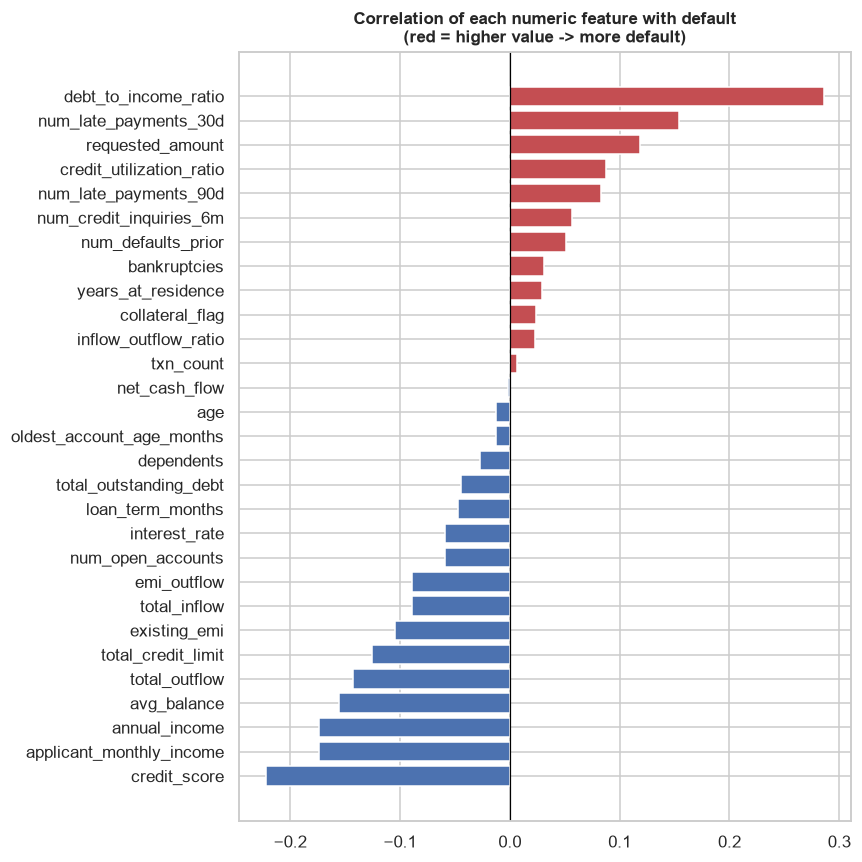

In [12]:
exclude = {"loan_default", "approved_amount", "disbursed_flag"}
num_all = [c for c in d.select_dtypes("number").columns if c not in exclude]
corr_t = d[num_all + ["loan_default"]].corr()["loan_default"].drop("loan_default").sort_values()

fig, ax = plt.subplots(figsize=(8, 8))
colors = ["#C44E52" if v > 0 else "#4C72B0" for v in corr_t.values]
ax.barh(corr_t.index, corr_t.values, color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Correlation of each numeric feature with default\n(red = higher value -> more default)")
plt.tight_layout(); plt.show()

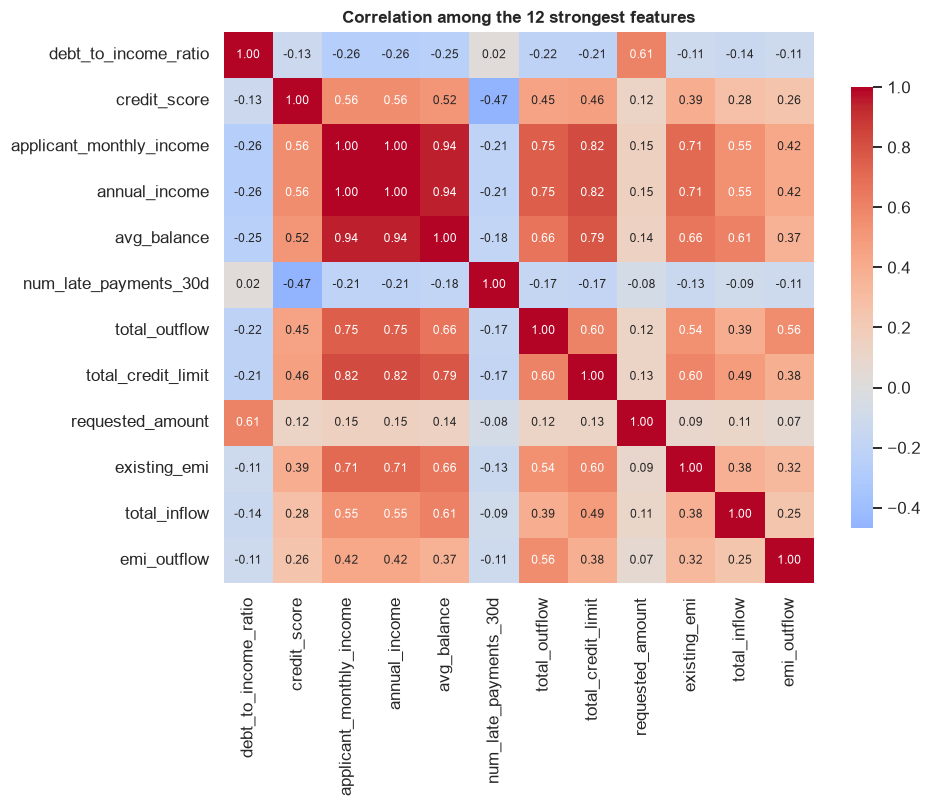

Feature pairs with |correlation| > 0.85 (redundant):
applicant_monthly_income  annual_income                1.000
age                       oldest_account_age_months    0.989
annual_income             avg_balance                  0.943
applicant_monthly_income  avg_balance                  0.943


In [13]:
# Correlation BETWEEN features: look for redundant pairs (multicollinearity)
top = corr_t.abs().sort_values(ascending=False).head(12).index.tolist()
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(d[top].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax,
            cbar_kws={"shrink": 0.8}, annot_kws={"size": 8})
ax.set_title("Correlation among the 12 strongest features")
plt.tight_layout(); plt.show()

pairs = d[num_all].corr().abs().where(np.triu(np.ones((len(num_all),) * 2), k=1).astype(bool)).stack()
print("Feature pairs with |correlation| > 0.85 (redundant):")
print(pairs[pairs > 0.85].sort_values(ascending=False).round(3).to_string())

## 10 · Traps to avoid in modelling
### 10.1 Customers with several loans
A customer can have more than one disbursed loan. If one customer's loans fall in both the training and the test set,
the model can "recognise" the customer and the test score becomes unrealistically good.

In [14]:
per_customer = d.groupby("customer_id").size()
print(per_customer.value_counts().sort_index().rename("customers").to_frame().rename_axis("disbursed loans per customer"))
print(f"\n{(per_customer > 1).sum():,} customers have 2+ disbursed loans "
      f"({d['customer_id'].duplicated().sum():,} 'extra' loan rows).")
print("-> We will split train/test BY CUSTOMER (GroupShuffleSplit / StratifiedGroupKFold), not by loan row.")

                              customers
disbursed loans per customer           
1                                  1500
2                                   583
3                                   176
4                                    43
5                                     5
6                                     2

809 customers have 2+ disbursed loans (1,094 'extra' loan rows).
-> We will split train/test BY CUSTOMER (GroupShuffleSplit / StratifiedGroupKFold), not by loan row.


### 10.2 Leakage columns
These fields only exist **after** the underwriting decision, so a model using them would be cheating:
`approval_status`, `approved_amount`, `decision_date`, `disbursed_flag`. For disbursed loans they carry no
information anyway (every one is *Approved* and *disbursed = 1*), but we still drop them explicitly.

In [15]:
print("approval_status values among disbursed loans:", d["approval_status"].unique().tolist())
print("disbursed_flag values:", d["disbursed_flag"].unique().tolist())
print(f"approved_amount / requested_amount: {(d['approved_amount'] / d['requested_amount']).min():.2f} to "
      f"{(d['approved_amount'] / d['requested_amount']).max():.2f}  (decided AFTER the application -> leakage risk)")

approval_status values among disbursed loans: ['Approved']
disbursed_flag values: [1]
approved_amount / requested_amount: 0.70 to 1.00  (decided AFTER the application -> leakage risk)


## 11 · Applications over time (all 7,500 applications)
This also previews the dashboard's *monthly applications* and *approval vs rejection* charts.

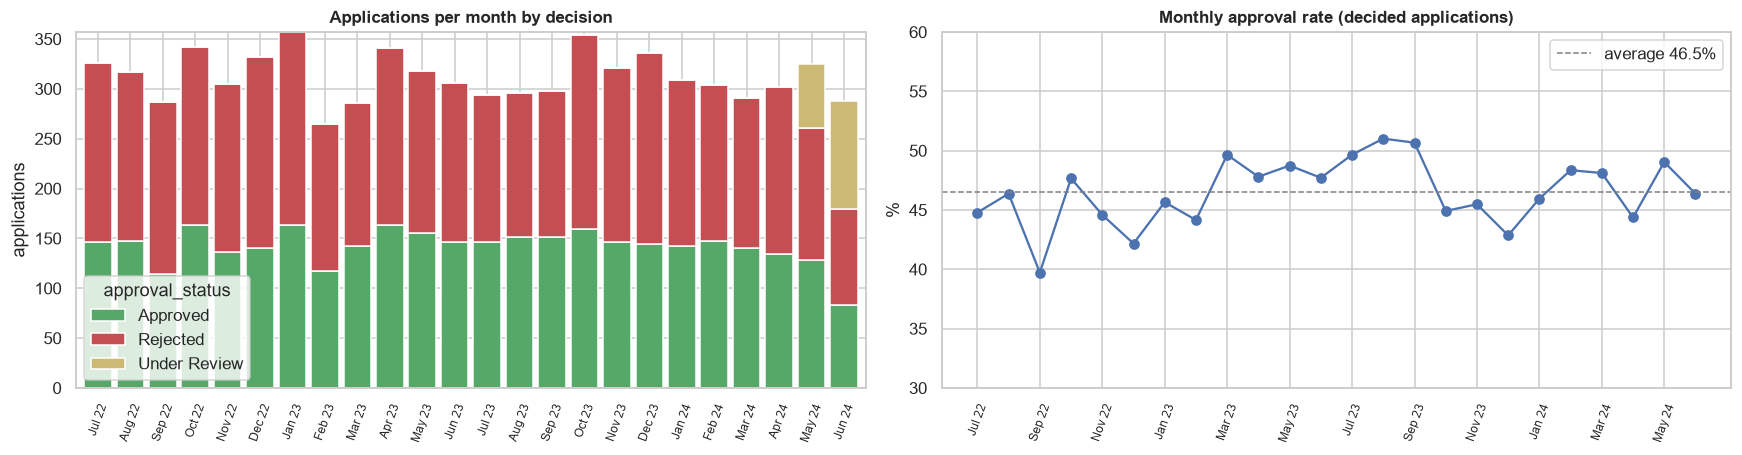

Under-review applications are only in the most recent months:
May 24     64
Jun 24    109


In [16]:
loans["month"] = loans["application_date"].dt.to_period("M")
status_m = loans.pivot_table(index="month", columns="approval_status", values="application_id", aggfunc="count").fillna(0)
status_m = status_m[["Approved", "Rejected", "Under Review"]]
labels = [p.strftime("%b %y") for p in status_m.index]
status_m.index = labels            # plain text labels avoid date-axis quirks

fig, ax = plt.subplots(1, 2, figsize=(16, 4.3))
status_m.plot(kind="bar", stacked=True, ax=ax[0], width=0.85,
              color={"Approved": "#55A868", "Rejected": "#C44E52", "Under Review": "#CCB974"})
ax[0].tick_params(axis="x", rotation=70, labelsize=8)
ax[0].set_title("Applications per month by decision"); ax[0].set_xlabel(""); ax[0].set_ylabel("applications")

decided = status_m[["Approved", "Rejected"]]
rate = decided["Approved"] / decided.sum(axis=1) * 100
ax[1].plot(range(len(rate)), rate.values, marker="o", color="#4C72B0")
ax[1].axhline(rate.mean(), color="grey", ls="--", lw=1, label=f"average {rate.mean():.1f}%")
ax[1].set_xticks(range(0, len(rate), 2)); ax[1].set_xticklabels(labels[::2], rotation=70, fontsize=8)
ax[1].set_ylim(30, 60); ax[1].legend(); ax[1].set_title("Monthly approval rate (decided applications)"); ax[1].set_ylabel("%")
plt.tight_layout(); plt.show()

print("Under-review applications are only in the most recent months:")
print(status_m["Under Review"][status_m["Under Review"] > 0].astype(int).to_string())

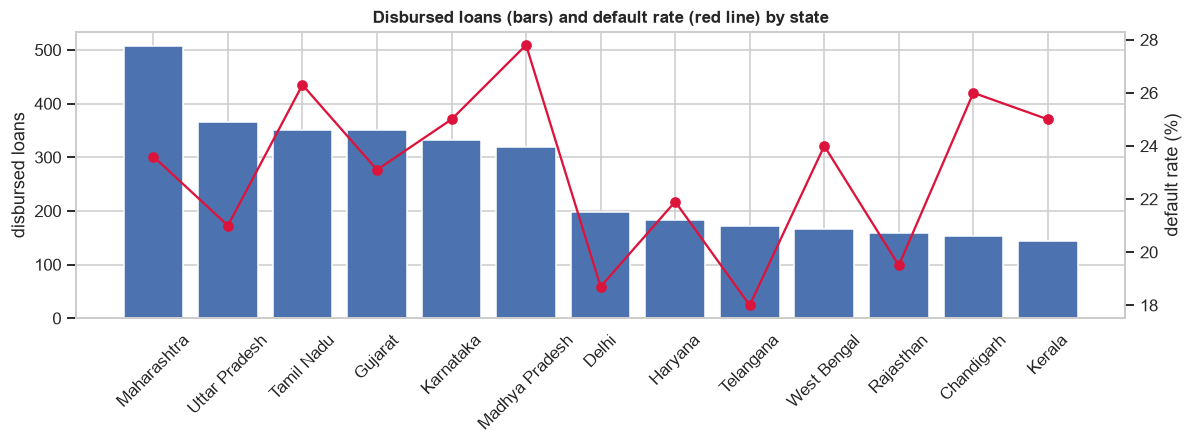

In [17]:
# Geography (dashboard component 5): loans and default rate by state
by_state = (d.groupby("state").agg(loans=("loan_default", "size"), default_rate=("loan_default", "mean"))
              .assign(default_rate=lambda x: (x["default_rate"] * 100).round(1)).sort_values("loans", ascending=False))
fig, ax = plt.subplots(figsize=(11, 4.2))
bars = ax.bar(by_state.index, by_state["loans"], color="#4C72B0")
ax.set_ylabel("disbursed loans"); ax.tick_params(axis="x", rotation=45)
ax2 = ax.twinx(); ax2.plot(by_state.index, by_state["default_rate"], color="crimson", marker="o"); ax2.set_ylabel("default rate (%)")
ax2.grid(False); ax.set_title("Disbursed loans (bars) and default rate (red line) by state")
plt.tight_layout(); plt.show()

## 12 · Key findings (computed from the data above)

In [18]:
def r(mask): return d.loc[mask, "loan_default"].mean() * 100

print(f"1. Class balance      : {BASE:.1f}% of {len(d):,} disbursed loans defaulted (imbalanced, so use ROC-AUC + recall).")
print(f"2. Credit score       : default {r(d.credit_score < 550):.0f}% below 550  vs  {r(d.credit_score >= 750):.0f}% at 750+.")
print(f"3. Debt-to-income     : default {r(d.debt_to_income_ratio <= 0.4):.0f}% when DTI <= 0.4  vs  {r(d.debt_to_income_ratio > 1.5):.0f}% when DTI > 1.5.")
print(f"4. Income             : default {r(d.annual_income < 300_000):.0f}% under 3L  vs  {r(d.annual_income >= 1_500_000):.0f}% at 15L+.")
print(f"5. Loan type          : riskiest = {rate_by('loan_type').sort_values('rate').iloc[-1]['loan_type']}, "
      f"safest = {rate_by('loan_type').sort_values('rate').iloc[0]['loan_type']}.")
print(f"6. Strongest linear drivers (|corr| with default): "
      + ", ".join(corr_t.abs().sort_values(ascending=False).head(5).index))
print(f"7. Multi-loan customers: {(per_customer > 1).sum():,} -> split by customer.")

1. Class balance      : 23.4% of 3,403 disbursed loans defaulted (imbalanced, so use ROC-AUC + recall).
2. Credit score       : default 46% below 550  vs  12% at 750+.
3. Debt-to-income     : default 11% when DTI <= 0.4  vs  46% when DTI > 1.5.
4. Income             : default 44% under 3L  vs  8% at 15L+.
5. Loan type          : riskiest = Home, safest = Personal.
6. Strongest linear drivers (|corr| with default): debt_to_income_ratio, credit_score, applicant_monthly_income, annual_income, avg_balance
7. Multi-loan customers: 809 -> split by customer.


## 13 · What this means for feature engineering (next notebook)
| Finding | Decision |
|---|---|
| Target is ~23% default | Use `class_weight="balanced"` / `scale_pos_weight`; judge on ROC-AUC and recall |
| Monthly income × 12 = annual income exactly | Keep **one** of them (they are redundant) |
| `age` and `oldest_account_age_months` are ~0.99 correlated | Keep **one** (or neither: age alone is enough) |
| `avg_balance` is ~0.94 correlated with income | It mostly restates income; keep it but expect little extra signal |
| Debt-to-income is capped at 3.0 and many defaulters sit at the cap | Keep the raw value; trees handle the cap fine, scaling is fine for logistic regression |
| Collateral and residence type barely change default rate | Keep them in the first model, but do not expect them to rank high |
| Customers can have several disbursed loans | Split train/test **by customer** to avoid leakage |
| Transactions are at transaction grain | Aggregate to one row per customer first (done as a preview above) |
| Only ~8 transactions per customer | Transaction features are noisy; EMI outflow and balance differ between groups, but largely track income |
| `approval_status`, `approved_amount`, `decision_date`, `disbursed_flag` are post-decision | **Drop** from the feature set |
| Email / phone / names | **Drop** (PII, not predictive) |
| DTI, credit score, income, late payments look strongest | Add ratios: debt-to-limit, loan-to-income, EMI-to-income |
| `credit_history` has a single snapshot date | The dashboard's "credit score trend" must use another time axis (e.g. by application month or customer tenure), not `as_of_date` |